# Sentinel-1 over Dhaka

S1 GRD (radar), IW mode. Bands VV and VH. Works through clouds.

In [1]:
import io
import requests
import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ee.Initialize(project="sentinel-exploration")

dhaka = ee.Geometry.Rectangle([90.33, 23.68, 90.55, 23.90])

def show(ax, image, vis, title, region=dhaka):
    url = image.getThumbURL({**vis, "region": region, "dimensions": 800, "format": "png"})
    png = requests.get(url).content
    ax.imshow(Image.open(io.BytesIO(png)).convert("RGBA"))
    ax.set_title(title)
    ax.axis("off")

## Images in 2026

In [2]:
s1 = (ee.ImageCollection("COPERNICUS/S1_GRD")
      .filterBounds(dhaka)
      .filterDate("2026-01-01", "2027-01-01")
      .filter(ee.Filter.eq("instrumentMode", "IW")))

print("total:", s1.size().getInfo())
print("satellite:", s1.aggregate_histogram("platform_number").getInfo())
print("pass:", s1.aggregate_histogram("orbitProperties_pass").getInfo())
print("relative orbit:", s1.aggregate_histogram("relativeOrbitNumber_start").getInfo())

total: 48
satellite: {'A': 28, 'D': 20}
pass: {'ASCENDING': 23, 'DESCENDING': 25}
relative orbit: {'114.0': 23, '150.0': 25}


S1A all year, S1D added from July 2026 (same tracks). Ascending = track 114, descending = track 150. Using ascending only so the viewing geometry stays the same.

In [3]:
s1_asc = s1.filter(ee.Filter.eq("orbitProperties_pass", "ASCENDING"))

## One image

In [4]:
first = s1_asc.filterDate("2026-02-01", "2026-03-01").first()

props = first.toDictionary().getInfo()
for key in ["platform_number", "instrumentMode", "orbitProperties_pass", "relativeOrbitNumber_start",
            "transmitterReceiverPolarisation", "resolution_meters"]:
    print(f"{key:32} {props[key]}")
print(first.bandNames().getInfo())

date = first.date().format("YYYY-MM-dd").getInfo()
image = s1_asc.filterDate(date, ee.Date(date).advance(1, "day")).mosaic()
print("date:", date)

platform_number                  A
instrumentMode                   IW
orbitProperties_pass             ASCENDING
relativeOrbitNumber_start        114
transmitterReceiverPolarisation  ['VV', 'VH']
resolution_meters                10
['VV', 'VH', 'angle']
date: 2026-02-12


## VV, VH and composite

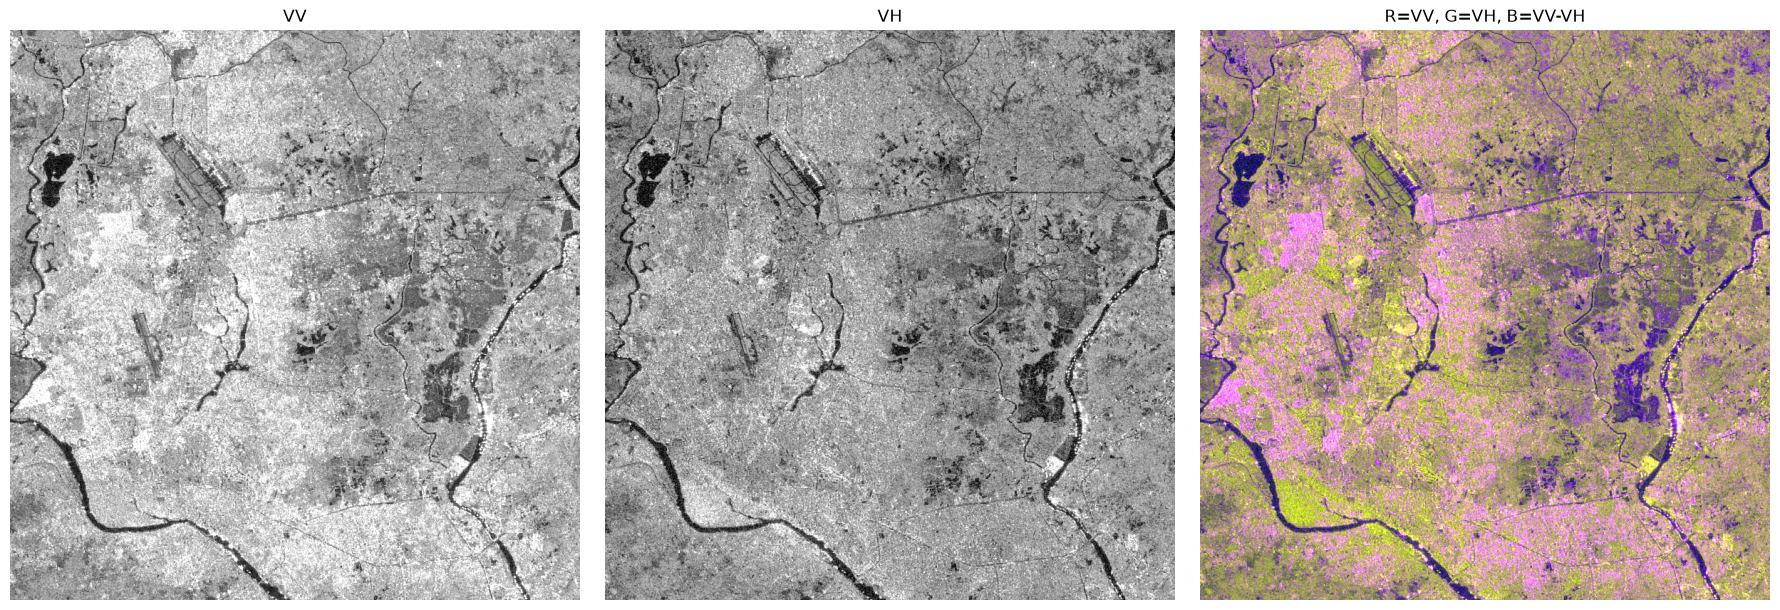

In [5]:
ratio = image.select("VV").subtract(image.select("VH")).rename("ratio")
image_rgb = image.addBands(ratio)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
show(axes[0], image.select("VV"), {"min": -25, "max": 0}, "VV")
show(axes[1], image.select("VH"), {"min": -30, "max": -5}, "VH")
show(axes[2], image_rgb, {"bands": ["VV", "VH", "ratio"], "min": [-25, -30, 0], "max": [0, -5, 15]}, "R=VV, G=VH, B=VV-VH")
plt.tight_layout()

## Speckle

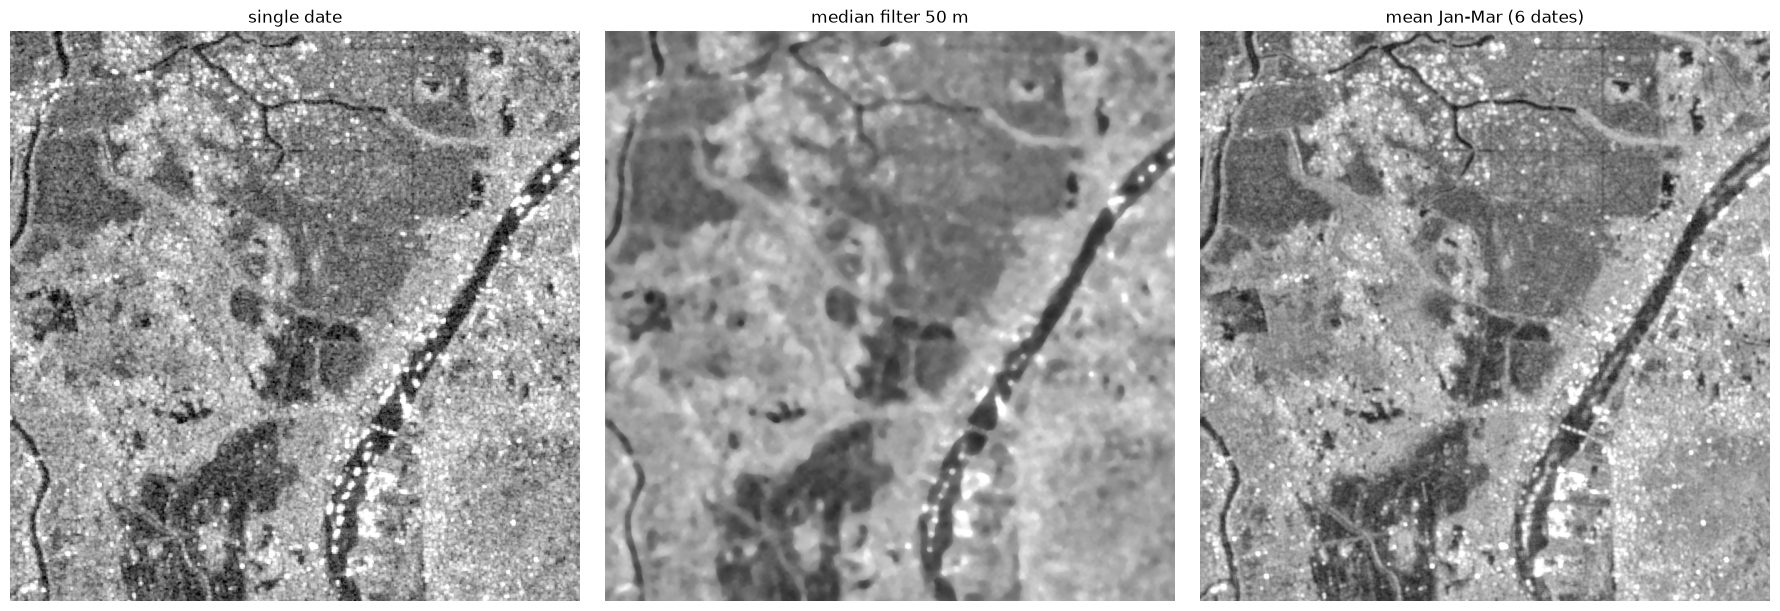

In [6]:
zoom = ee.Geometry.Rectangle([90.48, 23.76, 90.53, 23.81])

vv = image.select("VV")
vv_filtered = vv.focalMedian(50, "circle", "meters")
vv_mean = s1_asc.filterDate("2026-01-01", "2026-04-01").select("VV").mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
show(axes[0], vv, {"min": -25, "max": 0}, "single date", zoom)
show(axes[1], vv_filtered, {"min": -25, "max": 0}, "median filter 50 m", zoom)
show(axes[2], vv_mean, {"min": -25, "max": 0}, "mean Jan-Mar (6 dates)", zoom)
plt.tight_layout()

## Ascending vs descending

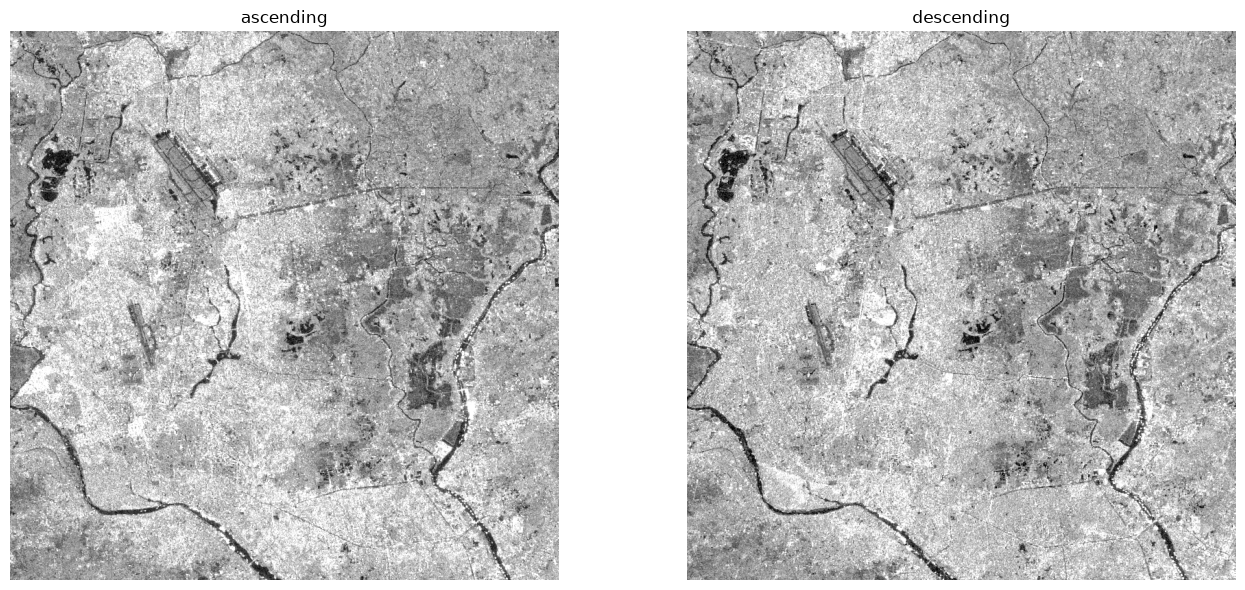

In [7]:
s1_desc = s1.filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
asc_img = s1_asc.filterDate("2026-02-01", "2026-03-01").mosaic()
desc_img = s1_desc.filterDate("2026-02-01", "2026-03-01").mosaic()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
show(axes[0], asc_img.select("VV"), {"min": -25, "max": 0}, "ascending")
show(axes[1], desc_img.select("VV"), {"min": -25, "max": 0}, "descending")
plt.tight_layout()